# Роль 3: Предсказание следующего клика и агент навигации


In [1]:
# Настройка окружения для Google Colab
import os, sys
from pathlib import Path

if "google.colab" in sys.modules:
    REPO_DIR = Path("/content/wikispeedia")
    if not REPO_DIR.exists():
        !git clone https://github.com/sammdog/wikispeedia.git /content/wikispeedia
        %cd /content/wikispeedia
        !pip install -q -r requirements.txt
        !python scripts/download_dataset.py
        !python scripts/build_dataset.py
    else:
        %cd /content/wikispeedia


In [2]:
import sys
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path("/content/wikispeedia") if "google.colab" in sys.modules else (Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.config import PROCESSED_DIR, FIGURES_DIR
from src.data_loader import load_articles, load_links
from src.graph_utils import build_graph

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.figsize"] = (10, 4.5)


## 1. Загрузка графа и матрицы семантического сходства TF-IDF


In [3]:
paths = pd.read_parquet(PROCESSED_DIR / "paths.parquet")
D = np.load(PROCESSED_DIR / "distance_matrix.npy")
tfidf_sim = np.load(PROCESSED_DIR / "tfidf_sim.npy")
with open(PROCESSED_DIR / "article_to_idx.json", encoding="utf-8") as f:
    article_to_idx = json.load(f)

articles = load_articles()
links = load_links()
G = build_graph(links, articles)

print(f"Граф G: {G.number_of_nodes():,} узлов, {G.number_of_edges():,} рёбер")
print(f"Матрица TF-IDF сходства: {tfidf_sim.shape}")


Граф G: 4,604 узлов, 119,882 рёбер
Матрица TF-IDF сходства: (4604, 4604)


## 2. Жадный TF-IDF агент навигации


In [4]:
def agent_path(start, target, max_steps=50):
    """Жадный агент: на каждом шаге выбирает соседа с максимальным сходством TF-IDF к target."""
    path = [start]
    cur = start
    visited = set([start])

    if target not in article_to_idx:
        return path, False

    target_idx = article_to_idx[target]

    for _ in range(max_steps):
        if cur == target:
            return path, True

        # Все доступные соседи по ссылкам
        nbrs = [v for v in G.successors(cur) if v in article_to_idx]
        # Исключаем посещённые, чтобы не зацикливаться
        nbrs = [v for v in nbrs if v not in visited]

        if not nbrs:
            return path, False  # Тупик

        # Быстрый O(1) поиск схожести по готовой матрице tfidf_sim
        nbr_indices = [article_to_idx[v] for v in nbrs]
        sims = tfidf_sim[target_idx, nbr_indices]

        best_idx = int(np.argmax(sims))
        nxt = nbrs[best_idx]

        path.append(nxt)
        visited.add(nxt)
        cur = nxt

    return path, cur == target


## 3. Сравнение TF-IDF агента с людьми на 100 тестовых парах


Запуск TF-IDF агента на 100 тестовых парах...

[Результаты эксперимента]:
  Успешность агента:  99/100 (99%)
  Средний оверхед агента: 1.53x
  Средний оверхед людей:  1.94x


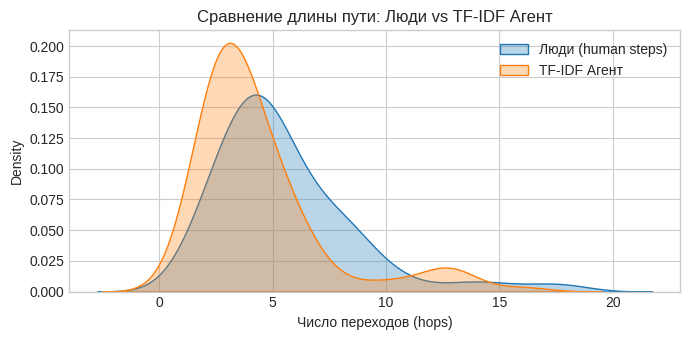

In [5]:
# Отбираем успешные партии людей
fin = paths[paths["finished"] == 1]
valid_human = []
for start, target, actual in zip(fin["start"], fin["target"], fin["n_steps"]):
    if start in article_to_idx and target in article_to_idx:
        sp = D[article_to_idx[start], article_to_idx[target]]
        if sp > 0:
            valid_human.append({"start": start, "target": target, "shortest": sp, "human_steps": actual, "human_ratio": actual / sp})

cmp_df = pd.DataFrame(valid_human)

# Семплируем 100 пар (как в исходном ноутбуке)
sample = cmp_df.sample(100, random_state=42).copy()

agent_success = 0
agent_overheads = []
agent_steps = []

print("Запуск TF-IDF агента на 100 тестовых парах...")
for _, row in sample.iterrows():
    st, tgt, sp = row["start"], row["target"], row["shortest"]
    path, ok = agent_path(st, tgt, max_steps=50)
    if ok:
        agent_success += 1
        steps = len(path) - 1
        agent_steps.append(steps)
        agent_overheads.append(steps / sp)

print(f"\n[Результаты эксперимента]:")
print(f"  Успешность агента:  {agent_success}/100 ({agent_success}%)")
if agent_overheads:
    print(f"  Средний оверхед агента: {np.mean(agent_overheads):.2f}x")
    print(f"  Средний оверхед людей:  {sample['human_ratio'].mean():.2f}x")

# Сравнение распределения длин путей
plt.figure(figsize=(7, 3.5))
sns.kdeplot(sample["human_steps"], label="Люди (human steps)", color="tab:blue", fill=True, alpha=0.3)
if agent_steps:
    sns.kdeplot(agent_steps, label="TF-IDF Агент", color="tab:orange", fill=True, alpha=0.3)
plt.title("Сравнение длины пути: Люди vs TF-IDF Агент")
plt.xlabel("Число переходов (hops)")
plt.legend()
plt.tight_layout()
plt.show()


## 4. Задача предсказания следующего клика (подготовка к КТ2)


In [6]:
print("""
Постановка задачи Роли 3 для КТ2/КТ3:
1. Объект: пара (текущая статья, ссылка-кандидат).
2. Метрики: top-1 и top-5 accuracy выбора правильной ссылки среди всех исходящих из текущей статьи.
3. Бейзлайн: выбор ссылки с максимальным TF-IDF сходством к цели (реализован выше).
4. Следующий шаг: ранжирующая модель на признаках Роли 1 (PageRank, степени, расстояние до цели).
""")



Постановка задачи Роли 3 для КТ2/КТ3:
1. Объект: пара (текущая статья, ссылка-кандидат).
2. Метрики: top-1 и top-5 accuracy выбора правильной ссылки среди всех исходящих из текущей статьи.
3. Бейзлайн: выбор ссылки с максимальным TF-IDF сходством к цели (реализован выше).
4. Следующий шаг: ранжирующая модель на признаках Роли 1 (PageRank, степени, расстояние до цели).

